| **Inicio**         | **atrás 3**                          |
| ------------------ |  -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./1_3_Calculo_integral.ipynb) |

# 0. Antes de empezar: ¿qué es realmente una serie?

Primero hay que distinguir:

### Sucesión

Una sucesión es una lista:

$$
a_1,a_2,a_3,\ldots
$$

Por ejemplo:

$$
a_n=\frac1n
$$

produce

$$
1,\frac12,\frac13,\frac14,\ldots
$$

### Serie

Una serie es la **suma** de los términos de una sucesión:

$$
\sum_{n=1}^{\infty}a_n
$$

Por ejemplo:

$$
1+\frac12+\frac14+\frac18+\cdots
$$

Aquí aparece una pregunta fundamental:

> ¿La suma infinita se acerca a un número finito?

Si sí, decimos que la serie **converge**.

Si no, **diverge**.

Esto será central para todo lo que viene.

# 1. Series geométricas

## 1.1 La idea

Una serie geométrica tiene la forma

$$
a+ar+ar^2+ar^3+\cdots
$$

o

$$
\sum_{n=0}^{\infty}ar^n
$$

donde:

* $(a)$ = primer término
* $(r)$ = razón común

Por ejemplo:

$$
2+1+\frac12+\frac14+\frac18+\cdots
$$

tenemos

$$
a=2,\qquad r=\frac12
$$

# 1.2 ¿Por qué puede tener una suma infinita?

Esto parece extraño.

Tenemos infinitos términos:

$$
2+1+\frac12+\frac14+\frac18+\cdots
$$

pero:

$$
2+1=3
$$

$$
3+\frac12=3.5
$$

$$
3.5+\frac14=3.75
$$

$$
3.75+\frac18=3.875
$$

y así sucesivamente.

La suma se acerca a:

$$
4
$$

Por tanto:

$$
\boxed{
\sum_{n=0}^{\infty}2\left(\frac12\right)^n=4
}
$$

# 1.3 Fórmula de la serie geométrica

Si

$$
|r|<1
$$

entonces:

$$
\boxed{
\sum_{n=0}^{\infty}ar^n
=
\frac{a}{1-r}
}
$$

Por ejemplo:

$$
\sum_{n=0}^{\infty}3\left(\frac14\right)^n
$$

es:

$$
\frac{3}{1-\frac14}
=
\frac{3}{\frac34}
=
4
$$

# 1.4 Derivación matemática

Consideremos:

$$
S_N=a+ar+ar^2+\cdots+ar^N
$$

Multiplicamos por $(r)$:

$$
rS_N=ar+ar^2+\cdots+ar^{N+1}
$$

Restamos:

$$
S_N-rS_N
=
a-ar^{N+1}
$$

entonces:

$$
S_N(1-r)=a(1-r^{N+1})
$$

por tanto:

$$
\boxed{
S_N=
a\frac{1-r^{N+1}}{1-r}
}
$$

Si:

$$
|r|<1
$$

entonces:

$$
r^{N+1}\rightarrow0
$$

y obtenemos:

$$
\boxed{
S=\frac{a}{1-r}
}
$$

# 1.5 ¿Qué ocurre si $(|r|\geq1)$?

### Caso 1

$$
r=1
$$

$$
1+1+1+1+\cdots
$$

diverge.

### Caso 2

$$
r=-1
$$

$$
1-1+1-1+\cdots
$$

no converge en el sentido usual.

### Caso 3

$$
r=2
$$

$$
1+2+4+8+16+\cdots
$$

crece indefinidamente.

Por tanto:

$$
\boxed{|r|<1}
$$

es la condición fundamental.

# 1.6 Ejemplo difícil: depreciación de un activo

Supongamos que una máquina tiene un valor inicial de:

$$
V_0=100\,000
$$

y cada año conserva el $(85\%)$ de su valor.

Entonces:

$$
V_n=100000(0.85)^n
$$

Si queremos calcular la suma de todos los valores anuales:

$$
100000+85000+72250+\cdots
$$

tenemos:

$$
\sum_{n=0}^{\infty}100000(0.85)^n
$$

Entonces:

$$
S=\frac{100000}{1-0.85}
$$

$$
\boxed{S=666666.67}
$$

Esto **no significa** que la máquina tenga ese valor físico. Es una suma matemática de valores anuales.

Este tipo de modelo aparece en:

* depreciación;
* descuentos;
* crecimiento poblacional;
* pagos financieros;
* propagación de señales;
* modelos iterativos.

# 1.7 Aplicación científica: procesos que se amortiguan

Supongamos:

$$
E_n=E_0(0.8)^n
$$

donde $(E_n)$ representa la energía restante después de cada etapa.

Entonces:

$$
E_0+E_1+E_2+\cdots
$$

es:

$$
E_0\sum_{n=0}^{\infty}(0.8)^n
$$

y:

$$
E_{\text{total}}
=
\frac{E_0}{1-0.8}
=
5E_0
$$

Este tipo de comportamiento aparece en sistemas con **decaimiento**.

# 1.8 Gráfica Python

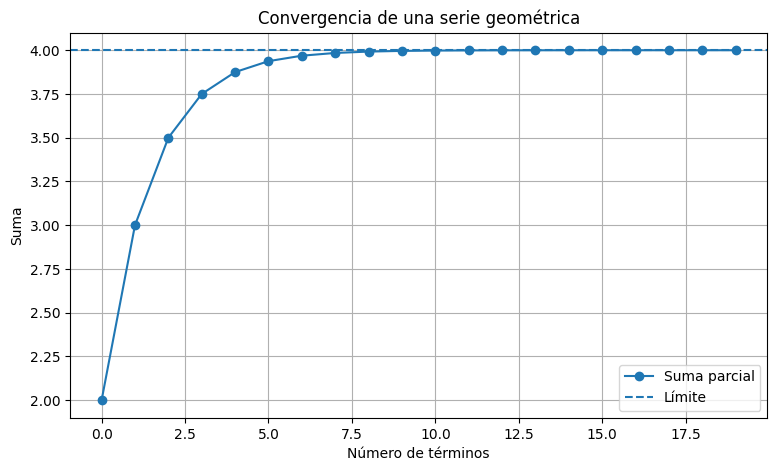

In [1]:
import numpy as np
import matplotlib.pyplot as plt

a = 2
r = 0.5

N = np.arange(0, 20)

partial_sums = np.array([
    np.sum(a * r**np.arange(n + 1))
    for n in N
])

exact = a / (1 - r)

plt.figure(figsize=(9, 5))

plt.plot(N, partial_sums, marker="o", label="Suma parcial")
plt.axhline(exact, linestyle="--", label="Límite")

plt.xlabel("Número de términos")
plt.ylabel("Suma")
plt.title("Convergencia de una serie geométrica")
plt.legend()
plt.grid()

plt.show()

Vas a observar cómo la suma parcial se aproxima progresivamente a:

$$
4
$$

# 2. Series de Taylor

Ahora entramos en una de las herramientas **más importantes de todo SciML**.

La idea fundamental es:

> Una función complicada puede aproximarse mediante un polinomio.

Por ejemplo:

$$
e^x
$$

puede representarse mediante:

$$
e^x
=
1+x+\frac{x^2}{2!}
+\frac{x^3}{3!}
+\frac{x^4}{4!}
+\cdots
$$

Esto permite convertir una función complicada en operaciones algebraicas.

# 2.1 Construcción desde derivadas

Supongamos que tenemos:

$$
f(x)
$$

y queremos aproximarla alrededor de:

$$
x=a
$$

Construimos:

$$
P_n(x)
=
f(a)
+
f'(a)(x-a)
+
\frac{f''(a)}{2!}(x-a)^2
+\cdots
$$

En general:

$$
\boxed{
f(x)
=
\sum_{n=0}^{\infty}
\frac{f^{(n)}(a)}{n!}(x-a)^n
}
$$

si la serie converge a la función.

# 2.2 Caso especial: Maclaurin

Si:

$$
a=0
$$

tenemos una serie de Maclaurin:

$$
\boxed{
f(x)
=
\sum_{n=0}^{\infty}
\frac{f^{(n)}(0)}{n!}x^n
}
$$

# 2.3 Ejemplo: $(e^x)$

Tenemos:

$$
f(x)=e^x
$$

y todas las derivadas son:

$$
f'(x)=e^x
$$

$$
f''(x)=e^x
$$

etc.

En $(x=0)$:

$$
f^{(n)}(0)=1
$$

por tanto:

$$
\boxed{
e^x=
1+x+\frac{x^2}{2!}
+\frac{x^3}{3!}
+\frac{x^4}{4!}
+\cdots
}
$$

# 2.4 Ejemplo difícil: aproximar $(e^{0.7})$

Tenemos:

$$
e^{0.7}
=
1+0.7+\frac{0.7^2}{2!}
+\frac{0.7^3}{3!}
+\cdots
$$

Usando solamente hasta $(n=4)$:

$$
P_4(0.7)
=
1+0.7+\frac{0.49}{2}
+\frac{0.343}{6}
+\frac{0.2401}{24}
$$

aproximadamente:

$$
P_4(0.7)\approx2.0137
$$

mientras:

$$
e^{0.7}\approx2.01375
$$

La aproximación es excelente.

# 2.5 ¿Por qué esto importa para SciML?

Porque muchas ecuaciones científicas contienen funciones complicadas:

$$
e^x,\quad
\sin x,\quad
\cos x,\quad
\log x
$$

y podemos aproximarlas mediante polinomios.

Los polinomios son extremadamente fáciles de:

* evaluar;
* derivar;
* integrar;
* implementar numéricamente;
* optimizar.

# 2.6 Ejemplo importante: $\sin(x)$

Sabemos:

$$
\sin(0)=0
$$

$$
\sin'(0)=1
$$

$$
\sin''(0)=0
$$

$$
\sin'''(0)=-1
$$

etc.

Entonces:

$$
\boxed{
\sin x
=
x-\frac{x^3}{3!}
+\frac{x^5}{5!}
-\frac{x^7}{7!}
+\cdots
}
$$

Observa algo interesante:

solo aparecen potencias impares.

# 2.7 Aproximar $\sin(0.8)$

Tomemos:

$$
P_3(x)=x-\frac{x^3}{6}
$$

Para $(x=0.8)$:

$$
P_3(0.8)
=
0.8-\frac{0.512}{6}
$$

$$
P_3(0.8)\approx0.71467
$$

Pero:

$$
\sin(0.8)\approx0.71736
$$

Si agregamos:

$$
\frac{x^5}{120}
$$

obtenemos una aproximación mucho mejor.

# 2.8 Gráfica Python: Taylor de $(e^x)$

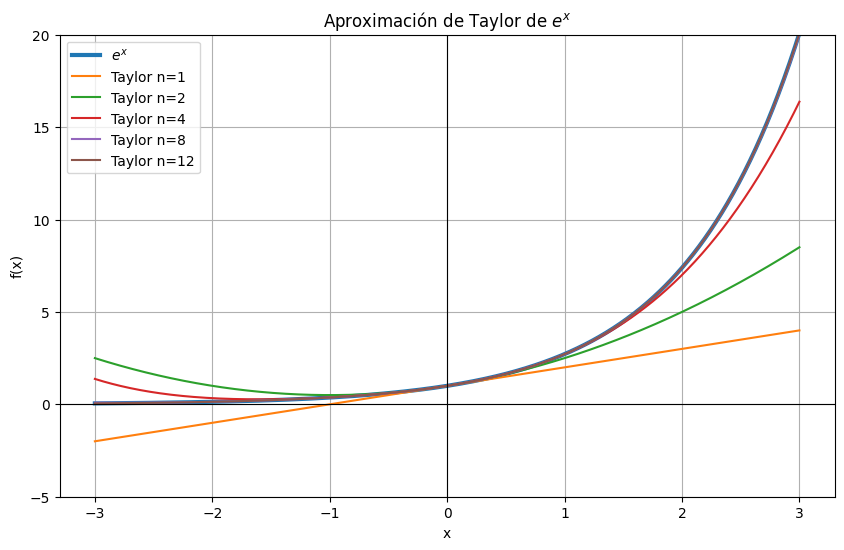

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial

x = np.linspace(-3, 3, 500)

exact = np.exp(x)

plt.figure(figsize=(10, 6))

plt.plot(x, exact, label="$e^x$", linewidth=3)

for n in [1, 2, 4, 8, 12]:

    approximation = sum(
        x**k / factorial(k)
        for k in range(n + 1)
    )

    plt.plot(
        x,
        approximation,
        label=f"Taylor n={n}"
    )

plt.ylim(-5, 20)
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Aproximación de Taylor de $e^x$")
plt.legend()
plt.grid(True)

plt.show()

Aquí aprenderás una idea fundamental:

> **más términos → generalmente mejor aproximación dentro de la región apropiada.**

Pero cuidado: esto nos lleva directamente al concepto de **convergencia**.

# 3. Convergencia

La convergencia es uno de los conceptos más importantes de análisis matemático.

Supongamos:

$$
S_N=\sum_{n=0}^{N}a_n
$$

La serie:

$$
\sum_{n=0}^{\infty}a_n
$$

converge si:

$$
\boxed{
\lim_{N\rightarrow\infty}S_N=S
}
$$

donde $(S)$ es un número finito.

# 3.1 Ejemplo

Consideremos:

$$
\sum_{n=1}^{\infty}\frac1{n^2}
$$

Tenemos:

$$
1+\frac14+\frac19+\frac1{16}+\cdots
$$

Esta serie converge.

De hecho:

$$
\boxed{
\sum_{n=1}^{\infty}\frac1{n^2}
=
\frac{\pi^2}{6}
}
$$

# 3.2 Pero cuidado con

$$
\sum_{n=1}^{\infty}\frac1n
$$

Tenemos:

$$
1+\frac12+\frac13+\frac14+\cdots
$$

Esta es la famosa **serie armónica**.

Aunque:

$$
\frac1n\rightarrow0
$$

la serie:

$$
\boxed{\sum_{n=1}^{\infty}\frac1n}
$$

diverge.

Esto es importantísimo.

# 3.3 Condición necesaria

Para que:

$$
\sum a_n
$$

converja necesariamente:

$$
\boxed{
a_n\rightarrow0
}
$$

Pero:

$$
a_n\rightarrow0
$$

**no garantiza** convergencia.

Por ejemplo:

$$
\frac1n\rightarrow0
$$

pero:

$$
\sum\frac1n
$$

diverge.

# 3.4 Serie $(p)$


Un resultado fundamental:

$$
\sum_{n=1}^{\infty}\frac1{n^p}
$$

converge si:

$$
\boxed{p>1}
$$

y diverge si:

$$
p\leq1
$$

Por ejemplo:

$$
\sum\frac1{n^{2}}
$$

converge.

Mientras:

$$
\sum\frac1{n^{0.5}}
$$

diverge.

# 3.5 ¿Por qué esto importa en SciML?

Porque los algoritmos numéricos producen aproximaciones:

$$
u_1,u_2,u_3,\ldots
$$

y queremos saber si:

$$
u_n\rightarrow u
$$

cuando aumentamos:

* resolución;
* número de iteraciones;
* términos;
* precisión;
* número de puntos.

Por ejemplo, en una simulación:

$$
h=\frac{1}{10}
$$

luego:

$$
h=\frac{1}{100}
$$

luego:

$$
h=\frac{1}{1000}
$$

Queremos estudiar:

$$
E(h)\rightarrow0
$$

# 4. Error de truncamiento

Ahora llegamos a algo **fundamental para Scientific Machine Learning**.

Cuando usamos una serie infinita, normalmente no calculamos infinitos términos.

Usamos:

$$
f(x)\approx P_N(x)
$$

y eliminamos el resto.

La diferencia es el **error de truncamiento**:

$$
\boxed{
R_N(x)=f(x)-P_N(x)
}
$$

# 4.1 Ejemplo

Para:

$$
e^x
$$

tenemos:

$$
e^x=
1+x+\frac{x^2}{2!}
+\frac{x^3}{3!}
+\cdots
$$

Si usamos:

$$
P_2(x)
=
1+x+\frac{x^2}{2}
$$

entonces:

$$
R_2(x)
=
e^x-P_2(x)
$$

# 4.2 Teorema de Taylor

Existe un punto $(\xi)$ entre $(a)$ y $(x)$ tal que:

$$
\boxed{
R_n(x)
=
\frac{f^{(n+1)}(\xi)}
{(n+1)!}
(x-a)^{n+1}
}
$$

Esta fórmula es extremadamente importante.

# 4.3 Ejemplo difícil

Aproximemos:

$$
e^{0.5}
$$

usando:

$$
P_4(x)
=
1+x+\frac{x^2}{2}
+\frac{x^3}{6}
+\frac{x^4}{24}
$$

El error real será:

$$
R_4(0.5)
=
e^{0.5}-P_4(0.5)
$$

Como:

$$
f^{(5)}(x)=e^x
$$

podemos obtener una cota.

Para:

$$
0\leq\xi\leq0.5
$$

tenemos:

$$
e^\xi\leq e^{0.5}
$$

por tanto:

$$
|R_4(0.5)|
\leq
\frac{e^{0.5}}{5!}(0.5)^5
$$

Esta cota nos dice **antes de calcular el resultado** qué tan grande puede ser el error.

Eso es importantísimo en computación científica.

# 4.4 Error absoluto

$$
\boxed{
E_{\text{abs}}
=
|x_{\text{real}}-x_{\text{aproximado}}|
}
$$

# 4.5 Error relativo

$$
\boxed{
E_{\text{rel}}
=
\frac{|x_{\text{real}}-x_{\text{aproximado}}|}
{|x_{\text{real}}|}
}
$$

y frecuentemente:

$$
E_{\text{rel}}\times100\%
$$

para expresarlo como porcentaje.

# 4.6 Gráfica del error de Taylor

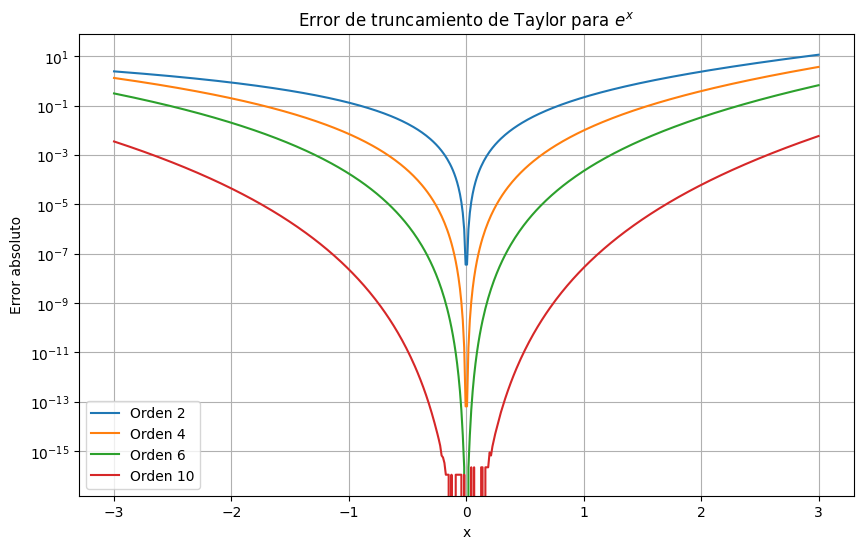

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import math

x = np.linspace(-3, 3, 500)

exact = np.exp(x)

plt.figure(figsize=(10, 6))

for n in [2, 4, 6, 10]:

    approximation = np.zeros_like(x)

    for k in range(n + 1):
        approximation += x**k / math.factorial(k)

    error = np.abs(exact - approximation)

    plt.semilogy(
        x,
        error,
        label=f"Orden {n}"
    )

plt.xlabel("x")
plt.ylabel("Error absoluto")
plt.title("Error de truncamiento de Taylor para $e^x$")
plt.legend()
plt.grid()

plt.show()

Usamos `semilogy()` porque los errores pueden variar varios órdenes de magnitud.

# 5. Algo MUY importante: convergencia de Taylor

No todas las series de Taylor funcionan igual.

Consideremos:

$$
f(x)=\frac1{1-x}
$$

Su serie alrededor de $(x=0)$ es:

$$
\boxed{
\frac1{1-x}
=
1+x+x^2+x^3+\cdots
}
$$

Pero solamente cuando:

$$
\boxed{|x|<1}
$$

## ¿Qué ocurre en $(x=2)$?

La serie sería:

$$
1+2+4+8+16+\cdots
$$

que diverge.

Sin embargo:

$$
\frac1{1-2}=-1
$$

La función existe en $(x=2)$, pero **la serie de Taylor alrededor de 0 no converge allí**.

Esto introduce un concepto muy importante:

### Radio de convergencia

La serie:

$$
\sum a_n(x-a)^n
$$

puede converger dentro de cierta distancia:

$$
\boxed{|x-a|<R}
$$

donde $(R)$ es el **radio de convergencia**.

Esto será muy importante cuando estudies:

* métodos espectrales;
* análisis complejo;
* PDE;
* aproximación numérica.


# 6. Series de Fourier

Ahora entramos en otro mundo.

Taylor aproxima una función mediante:

$$
1,x,x^2,x^3,\ldots
$$

Fourier utiliza:

$$
1,\sin x,\cos x,
\sin(2x),\cos(2x),
\sin(3x),\cos(3x),\ldots
$$

Es decir:

> Taylor utiliza polinomios. Fourier utiliza ondas.

# 6.1 Forma general

Una serie de Fourier para una función periódica es:

$$
\boxed{
f(x)
=
\frac{a_0}{2}
+
\sum_{n=1}^{\infty}
\left[
a_n\cos(nx)
+
b_n\sin(nx)
\right]
}
$$

para funciones con período:

$$
2\pi
$$

Los coeficientes son:

$$
\boxed{
a_n=
\frac1\pi
\int_{-\pi}^{\pi}
f(x)\cos(nx)\,dx
}
$$

y:

$$
\boxed{
b_n=
\frac1\pi
\int_{-\pi}^{\pi}
f(x)\sin(nx)\,dx
}
$$

# 6.2 ¿Por qué funciona?

Las funciones:

$$
\sin(nx)
$$

y:

$$
\cos(nx)
$$

son ortogonales.

Por ejemplo:

$$
\int_{-\pi}^{\pi}
\sin(nx)\sin(mx)\,dx
=0
$$

cuando:

$$
n\neq m
$$

Esto es análogo a tener vectores ortogonales en álgebra lineal.

Esta conexión es **muy importante para SciML**.

# 6.3 Ejemplo difícil: onda cuadrada

Consideremos:

$$
f(x)=
\begin{cases}
1 & 0<x<\pi\\
-1 & -\pi<x<0
\end{cases}
$$

Esta función es impar:

$$
f(-x)=-f(x)
$$

Por tanto:

$$
a_0=0
$$

y:

$$
a_n=0
$$

Solamente aparecen senos.

Calculamos:

$$
b_n
=
\frac1\pi
\int_{-\pi}^{\pi}
f(x)\sin(nx)\,dx
$$

resulta:

$$
b_n=
\begin{cases}
\frac4{n\pi},&n\text{ impar}\\
0,&n\text{ par}
\end{cases}
$$

Por tanto:

$$
\boxed{
f(x)
=
\frac4\pi
\left(
\sin x+
\frac{\sin3x}{3}
+
\frac{\sin5x}{5}
+
\cdots
\right)
}
$$

# 6.4 ¿Qué acaba de ocurrir?

Una onda cuadrada, que tiene saltos abruptos, fue representada como una suma de ondas suaves:

$$
\sin x
$$

$$
\frac{\sin3x}{3}
$$

$$
\frac{\sin5x}{5}
$$

etc.

Esto es increíblemente importante en:

* procesamiento de señales;
* acústica;
* electricidad;
* mecánica;
* dinámica de fluidos;
* transferencia de calor;
* ecuaciones diferenciales parciales;
* imágenes;
* métodos espectrales.

# 6.5 Gráfica Python

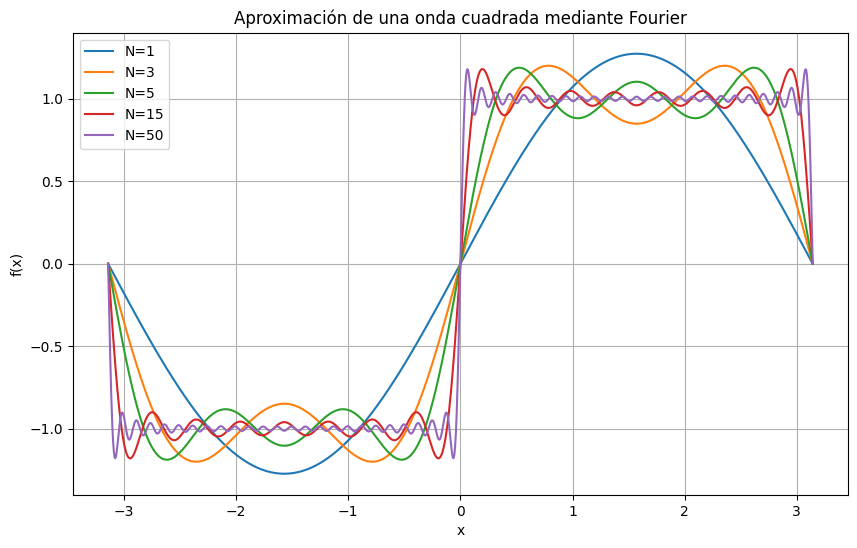

In [8]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-np.pi, np.pi, 2000)

plt.figure(figsize=(10, 6))

for N in [1, 3, 5, 15, 50]:

    f = np.zeros_like(x)

    for n in range(1, N + 1, 2):
        f += (4 / (np.pi * n)) * np.sin(n * x)

    plt.plot(
        x,
        f,
        label=f"N={N}"
    )

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Aproximación de una onda cuadrada mediante Fourier")
plt.legend()
plt.grid()

plt.show()

Al aumentar $(N)$, la aproximación se parece cada vez más a la onda cuadrada.

# 6.6 Pero aparece algo extraño: fenómeno de Gibbs

Cerca de los saltos aparecen oscilaciones.

Aunque agreguemos muchos términos:

$$
N\rightarrow\infty
$$

las oscilaciones cercanas al salto no desaparecen completamente de la manera intuitiva que uno podría esperar.

Esto se llama:

$$
\boxed{\text{Fenómeno de Gibbs}}
$$

Es muy importante en procesamiento de señales y métodos espectrales.

# 7. Aplicación real: procesamiento de audio

Supongamos que tienes una señal de audio:

$$
s(t)
$$

Una señal complicada puede descomponerse en frecuencias:

$$
s(t)
=
A_1\sin(\omega_1t)
+
A_2\sin(\omega_2t)
+
A_3\sin(\omega_3t)
+\cdots
$$

Esto permite estudiar:

* frecuencia fundamental;
* armónicos;
* ruido;
* frecuencias dominantes.

En computación normalmente utilizamos la **Transformada Discreta de Fourier (DFT)** y su implementación eficiente:

$$
\boxed{\text{FFT}}
$$

# 7.1 Ejemplo Python: señal compuesta

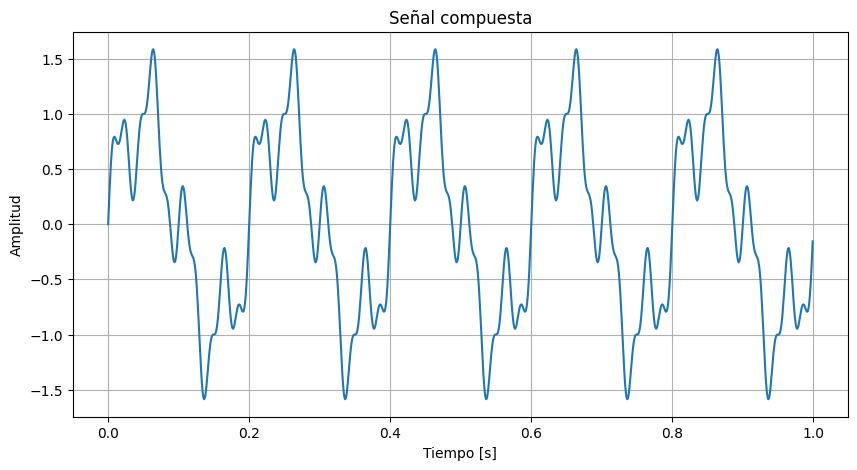

In [9]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000
t = np.arange(0, 1, 1/fs)

signal = (
    np.sin(2*np.pi*5*t)
    + 0.5*np.sin(2*np.pi*20*t)
    + 0.2*np.sin(2*np.pi*50*t)
)

plt.figure(figsize=(10, 5))

plt.plot(t, signal)

plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.title("Señal compuesta")
plt.grid()

plt.show()

Tenemos tres frecuencias:

$$
5\text{ Hz}
$$

$$
20\text{ Hz}
$$

$$
50\text{ Hz}
$$

# 7.2 Analizarla mediante FFT

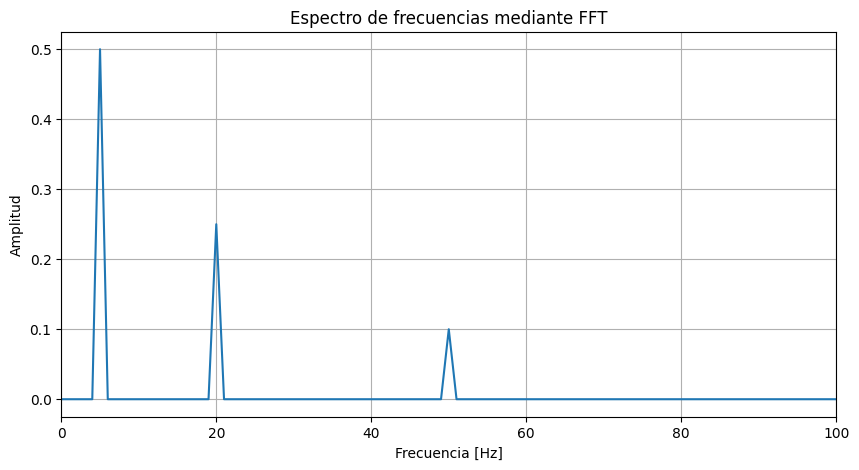

In [10]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000
t = np.arange(0, 1, 1/fs)

signal = (
    np.sin(2*np.pi*5*t)
    + 0.5*np.sin(2*np.pi*20*t)
    + 0.2*np.sin(2*np.pi*50*t)
)

N = len(signal)

frequencies = np.fft.rfftfreq(N, 1/fs)

spectrum = np.abs(
    np.fft.rfft(signal)
) / N

plt.figure(figsize=(10, 5))

plt.plot(frequencies, spectrum)

plt.xlim(0, 100)

plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Amplitud")
plt.title("Espectro de frecuencias mediante FFT")
plt.grid()

plt.show()

Vas a observar picos aproximadamente en:

$$
5,\quad20,\quad50\text{ Hz}
$$

Esto es Fourier en acción.

# 8. Fourier aplicado a una ecuación diferencial parcial

Aquí empieza la conexión realmente fuerte con **SciML**.

Supongamos la ecuación del calor:

$$
\boxed{
\frac{\partial u}{\partial t}
=
\alpha
\frac{\partial^2u}{\partial x^2}
}
$$

donde:

* $u(x,t)$ = temperatura;
* $(\alpha)$ = difusividad térmica.

Una forma de resolver esta PDE es expresar:

$$
u(x,t)
$$

como combinación de funciones sinusoidales:

$$
u(x,t)
=
\sum_{n=1}^{\infty}
c_n(t)\sin(nx)
$$

Esto convierte una PDE en un conjunto de ecuaciones para los coeficientes:

$$
c_1(t),c_2(t),c_3(t),\ldots
$$

Esto es una idea central de los **métodos espectrales**.

# 9. Taylor vs Fourier

Es muy importante que aprendas a distinguirlas.

| Taylor                                     | Fourier                                       |
| ------------------------------------------ | --------------------------------------------- |
| Polinomios                                 | Senos y cosenos                               |
| Aproximación local                         | Representación de frecuencias                 |
| Centrada alrededor de $(a)$                | Naturalmente periódica                        |
| Excelente para funciones suaves localmente | Excelente para señales y PDE                  |
| Derivadas determinan coeficientes          | Integrales/proyección determinan coeficientes |
| Métodos numéricos                          | Métodos espectrales                           |
| Expansión local                            | Descomposición global                         |

Por ejemplo:

### Taylor

$$
e^x
\approx
1+x+\frac{x^2}{2}+\cdots
$$

### Fourier

$$
f(x)
\approx
a_0+
a_1\cos x+
b_1\sin x+\cdots
$$

Son dos formas diferentes de construir aproximaciones.

# 10. Conexión con álgebra lineal

Esta conexión te va a resultar especialmente importante para SciML.

Imagina que tienes un vector:

$$
\mathbf{x}
$$

y quieres escribirlo usando una base:

$$
\mathbf{x}
=
c_1\mathbf{v}_1+
c_2\mathbf{v}_2+
\cdots
$$

Eso es exactamente la idea de Fourier:

$$
f(x)
=
c_0
+
c_1\sin x
+
c_2\cos x
+\cdots
$$

Estamos expresando una función en una **base de funciones**.

Por eso Fourier está íntimamente conectado con:

* álgebra lineal;
* espacios vectoriales;
* producto interno;
* ortogonalidad;
* proyecciones;
* eigenfunctions;
* operadores.

Y esto después aparecerá en:

$$
\boxed{
\text{PDE}
\rightarrow
\text{métodos espectrales}
\rightarrow
\text{SciML}
}
$$

# 11. Cómo aparece el error en SciML

Supongamos que tenemos una solución verdadera:

$$
u(x)
$$

y una aproximación:

$$
u_N(x)
$$

Entonces podemos medir:

$$
e_N(x)=u(x)-u_N(x)
$$

Una métrica muy importante es la norma $(L^2)$:

$$
\boxed{
\|e_N\|_{L^2}
=
\sqrt{
\int_a^b
|u(x)-u_N(x)|^2dx
}
}
$$

En código:

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial


# Dominio
x = np.linspace(-3, 3, 500)


# Solución exacta
u_exact = np.exp(x)


# Aproximación de Taylor
n = 8

u_approx = sum(
    x**k / factorial(k)
    for k in range(n + 1)
)


# Error L2 mediante integración numérica
error = np.sqrt(
    np.trapezoid(
        (u_exact - u_approx)**2,
        x
    )
)

print("Error L2 =", error)

Error L2 = 0.034151116993861245


Esto es exactamente el tipo de métrica que encontrarás posteriormente en:

* simulaciones PDE;
* PINNs;
* Neural Operators;
* métodos espectrales;
* DeepONet;
* Scientific Machine Learning.

# 12. Comparando convergencia de Taylor

Podemos hacer un pequeño experimento científico.

Queremos aproximar:

$$
e^{0.8}
$$

y estudiar el error al aumentar el número de términos.

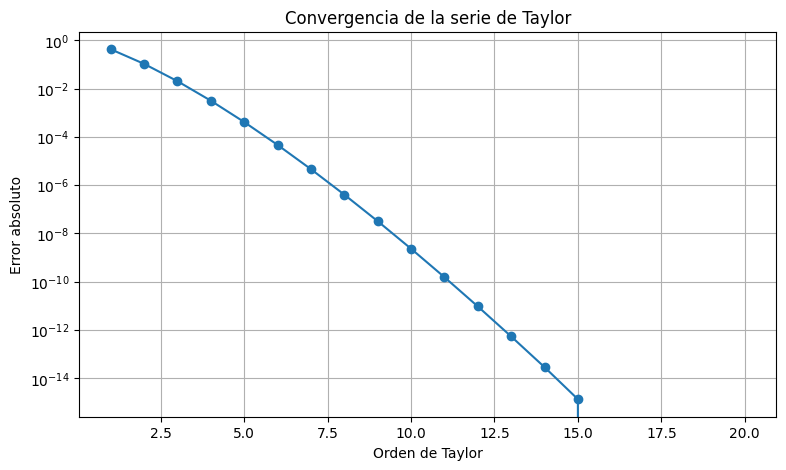

In [13]:
import numpy as np
import math
import matplotlib.pyplot as plt

x = 0.8

exact = np.exp(x)

orders = np.arange(1, 21)
errors = []

for n in orders:

    approximation = sum(
        x**k / math.factorial(k)
        for k in range(n + 1)
    )

    error = abs(exact - approximation)

    errors.append(error)

plt.figure(figsize=(9, 5))

plt.semilogy(
    orders,
    errors,
    marker="o"
)

plt.xlabel("Orden de Taylor")
plt.ylabel("Error absoluto")
plt.title("Convergencia de la serie de Taylor")
plt.grid()

plt.show()

Aquí estás haciendo algo mucho más importante que simplemente "dibujar una gráfica".

Estás realizando un **experimento numérico de convergencia**.

# 13. Error de truncamiento vs error numérico

En SciML debes aprender a distinguirlos.

## Error de truncamiento

Proviene de cortar una representación infinita:

$$
f(x)
\rightarrow
P_N(x)
$$

$$
\boxed{
E_{\text{trunc}}
=
f-P_N
}
$$

## Error de redondeo

Proviene de la representación finita de números en el computador.

Por ejemplo:

$$
0.1
$$

no puede representarse exactamente en muchos sistemas de punto flotante binario.

## Error total

En problemas numéricos podemos encontrar algo parecido a:

$$
\boxed{
E_{\text{total}}
\approx
E_{\text{truncamiento}}
+
E_{\text{redondeo}}
+
E_{\text{discretización}}
}
$$

Esto es fundamental.

Porque aumentar la precisión de un método no siempre significa que el error computacional seguirá disminuyendo indefinidamente.

# 14. Un ejemplo muy importante para SciML

Supongamos que resolvemos una PDE usando:

$$
N=10
$$

modos de Fourier.

Tenemos:

$$
E_{10}=10^{-2}
$$

Aumentamos:

$$
N=20
$$

y:

$$
E_{20}=10^{-4}
$$

Luego:

$$
N=40
$$

y:

$$
E_{40}=10^{-8}
$$

Estamos observando convergencia rápida.

Pero si en lugar de Fourier utilizamos otro método quizá tengamos:

$$
E_N\sim\frac1{N^2}
$$

Mientras otro método puede tener:

$$
E_N\sim e^{-cN}
$$

La **tasa de convergencia** importa muchísimo en computación científica.

# 15. Resumen matemático

## Serie geométrica

$$
\boxed{
\sum_{n=0}^{\infty}ar^n
=
\frac{a}{1-r}
}
$$

si:

$$
|r|<1
$$

## Taylor

$$
\boxed{
f(x)
=
\sum_{n=0}^{\infty}
\frac{f^{(n)}(a)}{n!}(x-a)^n
}
$$

## Convergencia

$$
\boxed{
\lim_{N\rightarrow\infty}S_N=S
}
$$

## Error de truncamiento

$$
\boxed{
R_N=f-P_N
}
$$

y mediante Taylor:

$$
\boxed{
R_n(x)=
\frac{f^{(n+1)}(\xi)}
{(n+1)!}
(x-a)^{n+1}
}
$$

## Fourier

$$
\boxed{
f(x)=
\frac{a_0}{2}
+
\sum_{n=1}^{\infty}
[a_n\cos(nx)+b_n\sin(nx)]
}
$$

| **Inicio**         | **atrás 3**                          |
| ------------------ |  -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./1_3_Calculo_integral.ipynb) |